## Data preparation & EDA

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

from tqdm.auto import tqdm

In [2]:
df = pd.read_csv('data/aps_failure_training_set.csv')

In [3]:
df.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,na,2130706438,280,0,0,0,0,0,...,1240520,493384,721044,469792,339156,157956,73224,0,0,0
1,neg,33058,na,0,na,0,0,0,0,0,...,421400,178064,293306,245416,133654,81140,97576,1500,0,0
2,neg,41040,na,228,100,0,0,0,0,0,...,277378,159812,423992,409564,320746,158022,95128,514,0,0
3,neg,12,0,70,66,0,10,0,0,0,...,240,46,58,44,10,0,0,0,4,32
4,neg,60874,na,1368,458,0,0,0,0,0,...,622012,229790,405298,347188,286954,311560,433954,1218,0,0


In [4]:
df['class'].value_counts(normalize=True)

class
neg    0.983333
pos    0.016667
Name: proportion, dtype: float64

In [5]:
df=df.rename(columns={'class': 'failure'})
df.failure = (df.failure == 'pos').astype(int)

In [6]:
column_names=df.columns
column_names=column_names.drop('failure')

In [7]:
for col in column_names:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df.head()

,failure,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,0,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,0,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,0,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,0,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,0,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [8]:
number_isna=df[column_names].isna().sum()
df.isna().sum().sort_values()

failure        0
aa_000         0
bt_000       167
ci_000       338
cj_000       338
           ...  
cr_000     46329
bo_000     46333
bp_000     47740
bq_000     48722
br_000     49264
Length: 171, dtype: int64

In [9]:
corr_val=df[column_names].corrwith(df.failure).abs()

C:\Users\gabi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\gabi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [10]:
for col in column_names:
    print(col, number_isna[col], corr_val[col])

aa_000 0 0.5369783925131116
ab_000 46329 0.03189609336029866
ac_000 3335 0.03653323441514123
ad_000 14861 0.0004150628013116259
ae_000 2500 0.00887256617080349
af_000 2500 0.022531811757200655
ag_000 671 0.012367940966279823
ag_001 671 0.19145294893300752
ag_002 671 0.34061089873985234
ag_003 671 0.43386894513882124
ag_004 671 0.3722879633373949
ag_005 671 0.44907479164162
ag_006 671 0.36908091629960454
ag_007 671 0.24224639661460634
ag_008 671 0.11310402903356298
ag_009 671 0.07220237807186325
ah_000 645 0.5245905526281477
ai_000 629 0.12103990032124794
aj_000 629 0.024478392017677764
ak_000 4400 0.018274783847176367
al_000 642 0.37396630541449993
am_0 629 0.3800326064194964
an_000 642 0.5243573995687995
ao_000 589 0.5198895389036868
ap_000 642 0.5157255150103903
aq_000 589 0.5311345698860787
ar_000 2723 0.18526571447361823
as_000 629 0.04410515064467019
at_000 629 0.13913498969504104
au_000 629 0.09313679837210004
av_000 2500 0.15696683692117158
ax_000 2501 0.14217515013729032
ay_000

In [11]:
feature = pd.DataFrame({"num_nan": number_isna, "corr_val": corr_val,"mean": df[column_names].mean()})

In [12]:
feature.sort_values(by='corr_val',ascending=True)[:80]

,num_nan,corr_val,mean
cs_008,669,0.000091,211.747350
co_000,14861,0.000411,190515.566938
ad_000,14861,0.000415,190620.639314
cf_000,14861,0.000416,190221.810984
cs_009,669,0.000545,779.197755
...,...,...,...
dg_000,4008,0.192798,5609.957030
cn_006,687,0.195377,410564.086760
dr_000,2726,0.198608,203759.847924
bz_000,2723,0.201048,101960.837788


In [13]:
df=df.fillna(df[column_names].mean())

In [14]:
important_feature=feature[feature.corr_val>0.2].index.tolist()
important_feature.append('failure')
df_use=df[important_feature]

In [15]:
df_train, df_val = train_test_split(df_use, test_size=0.25, random_state=1)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

y_train = df_train.failure.values
y_val = df_val.failure.values

del df_train['failure']
del df_val['failure']

In [16]:
cost1=10
cost2=500
def cost(y_val,y_pred,t=0.5):
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >=t)
    predict_negative = (y_pred < t)

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
#    print(fp, fn)
    return cost1*fp+cost2*fn

## Regression

### Logistic Regression

In [17]:
dv = DictVectorizer(sparse=False)

dicts_train = df_train.to_dict(orient='records')
X_train = dv.fit_transform(dicts_train)

dicts_val = df_val.to_dict(orient='records')
X_val = dv.fit_transform(dicts_val)

In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)  
X_val_sc= scaler.fit_transform(X_val) 

In [19]:
model = LogisticRegression(C=1, max_iter=1000)
model.fit(X_train_sc, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [20]:
y_pred = model.predict_proba(X_val_sc)[:, 1]
failure_decision = (y_pred >= 0.5)
(failure_decision == y_val).mean()

np.float64(0.9913333333333333)

In [21]:
roc_auc_score(y_val, y_pred)

0.966163406156393

In [22]:
cost(y_val,y_pred,0.5)

np.int64(48830)

#### Dummy model and cost function investigation

In [23]:
cost(y_val,0*y_pred,0.5)

np.int64(119000)

In [24]:
roc_auc_score(y_val, 0*y_pred)

0.5

In [25]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [26]:
scores=[]
scores_dum=[]
thresholds = np.linspace(0, 0.1, 101)

for t in thresholds:
    cost_val=cost(y_val,y_pred,t)
    cost_val_dum=cost(y_val,y_pred*0,t)
    scores.append(cost_val)
    scores_dum.append(cost_val_dum)

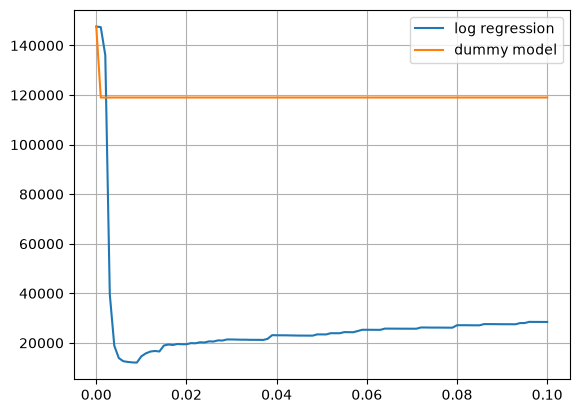

In [27]:
plt.plot(thresholds, scores, label='log regression')
plt.plot(thresholds, scores_dum, label='dummy model')
plt.legend()
plt.grid()

In [28]:
def for_thresh(thresholds,y_val,y_pred):
    scores=[]
    for t in thresholds:
        cost_val=cost(y_val,y_pred,t)
        scores.append(cost_val) 
    return scores

In [29]:
def cost_tresh(y_val,y_pred):
    tmax=0.1
    thresholds = np.linspace(0, tmax, 1001)
    scores=for_thresh(thresholds,y_val,y_pred)
    min_score=min(scores)
    n=0
    while (min_score==scores[1] or min_score==scores[-1]) and n<4:
        if min_score==scores[1]:
            print('min is smaller than range')
            tmax=tmax/10
            thresholds = np.linspace(0, tmax, 1001)
            scores=for_thresh(thresholds,y_val,y_pred)
            min_score=min(scores)
        elif min_score==scores[-1]:
            print('min is bigger than range')
            tmax=tmax*10
            thresholds = np.linspace(0, tmax, 1001)
            scores=for_thresh(thresholds,y_val,y_pred)
            min_score=min(scores)
        n+=1
    return min_score, thresholds[scores.index(min_score)]

In [30]:
cost_tresh(y_val,y_pred)

(np.int64(11790), np.float64(0.0077))

### Train Logistic Regression

In [31]:
def train(X_train, y_train, df_val, C=1.0):
    dicts = df_train.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)  


    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train_sc, y_train)

    dicts_val = df_val.to_dict(orient='records')

    X = dv.transform(dicts_val)
    X_val_sc= scaler.fit_transform(X_val) 
    y_pred = model.predict_proba(X_val_sc)[:, 1]

    return y_pred

In [32]:
y_pred=train(X_train, y_train, df_val)

In [33]:
cost_tresh(y_val,y_pred)

(np.int64(11790), np.float64(0.0077))

In [34]:
scores=[]
cost_list=[]
tresh=[]
for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]:
    y_pred=train(X_train, y_train, df_val,C)
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)
    cost_c, tresh= cost_tresh(y_val,y_pred)
    cost_list.append(cost_c)
    print('C=%s cost=%.3f t=%.3f, auc=%.3f' % (C, cost_c,tresh, auc ))

C=0.001 cost=11130.000 t=0.011, auc=0.985
C=0.01 cost=12010.000 t=0.010, auc=0.983
C=0.1 cost=11470.000 t=0.007, auc=0.972
C=0.5 cost=11730.000 t=0.009, auc=0.966
C=1 cost=11790.000 t=0.008, auc=0.966
C=5 cost=12130.000 t=0.006, auc=0.966
C=10 cost=12270.000 t=0.008, auc=0.966


# Trees

## Decision tree classifier

In [35]:
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, 30, 50, None]

for depth in depths: 
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    cost_c, tresh= cost_tresh(y_val,y_pred)
    
    print('%4s -> %.3f cost=%.3f, t=%.3f' % (depth, auc, cost_c, tresh))

min is bigger than range
   1 -> 0.864 cost=32790.000, t=0.005
min is bigger than range
   2 -> 0.906 cost=23520.000, t=0.003
min is bigger than range
   3 -> 0.921 cost=20660.000, t=0.003
   4 -> 0.931 cost=18920.000, t=0.002
   5 -> 0.926 cost=19380.000, t=0.002
   6 -> 0.914 cost=20640.000, t=0.002
  10 -> 0.826 cost=29410.000, t=0.001
  15 -> 0.770 cost=37100.000, t=0.001
  20 -> 0.708 cost=39360.000, t=0.003
min is bigger than range
min is bigger than range
  30 -> 0.820 cost=37170.000, t=0.020
min is smaller than range
min is smaller than range
min is smaller than range
min is smaller than range
  50 -> 0.842 cost=37710.000, t=0.000
min is smaller than range
min is smaller than range
min is smaller than range
min is smaller than range
None -> 0.834 cost=39680.000, t=0.000


In [36]:
scores = []

for depth in [5, 6, 7, 8, 9, 10]:
    for s in [1, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        cost_c, tresh= cost_tresh(y_val,y_pred)
        
        scores.append((depth, s, auc, cost_c, tresh))

In [37]:
columns = ['max_depth', 'min_samples_leaf', 'auc', 'cost_c', 'tresh']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores.sort_values(by='cost_c').head()

,max_depth,min_samples_leaf,auc,cost_c,tresh
14,6,200,0.974288,12020,0.0045
30,8,200,0.976292,12020,0.0161
46,10,200,0.979792,12020,0.0161
22,7,200,0.968434,12400,0.0161
38,9,200,0.975930,12400,0.0161


<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

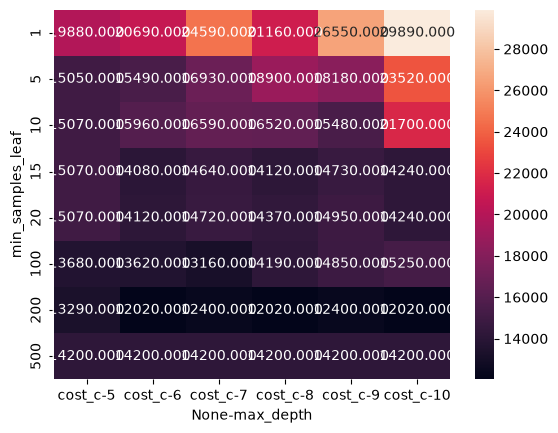

In [38]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['cost_c'])
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

In [39]:
cost_tresh(y_val,y_pred)

(np.int64(14200), np.float64(0.0252))

## Random forest classifier

In [41]:
scores = []

for d in tqdm([5,10,15,20]):
    for n in range(10, 201, 40):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1,n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        cost_c, tresh= cost_tresh(y_val,y_pred)

        scores.append((d, n, auc, cost_c, tresh))

  0%|          | 0/4 [00:00<?, ?it/s]

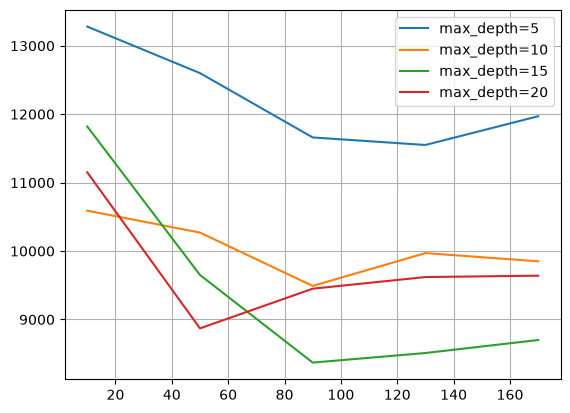

In [42]:
columns = ['max_depth', 'n_estimators', 'auc','cost', 't']
df_scores = pd.DataFrame(scores, columns=columns)
for d in [5,10,15,20]:
    df_subset = df_scores[df_scores.max_depth == d]
    
    plt.plot(df_subset.n_estimators, df_subset.cost,
             label='max_depth=%d' % d)

plt.legend()
plt.grid()

In [43]:
max_depth=15

In [44]:
scores = []

for s in tqdm([1, 3, 5, 10, 50]):
    for n in range(10, 201, 40):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1,n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        cost_c, tresh= cost_tresh(y_val,y_pred)

        scores.append((s, n, auc,cost_c, tresh))

  0%|          | 0/5 [00:00<?, ?it/s]

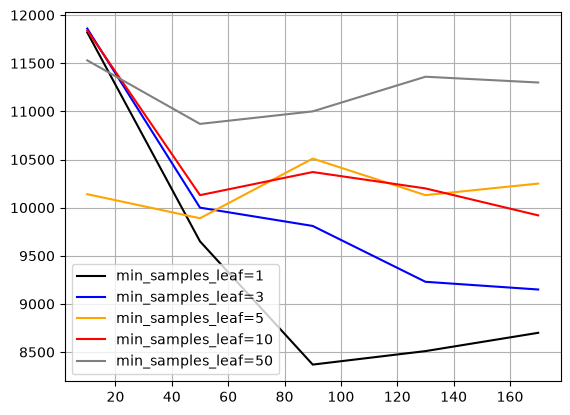

In [45]:
columns = ['min_samples_leaf', 'n_estimators', 'auc','cost',tresh]
df_scores = pd.DataFrame(scores, columns=columns)
colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    
    plt.plot(df_subset.n_estimators, df_subset.cost,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()
plt.grid()

In [46]:
min_samples_leaf = 1

### Final randomforest model

In [47]:
min_samples_leaf = 1
max_depth=15
scores = []
for n in tqdm(range(10, 201, 10)):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=min_samples_leaf ,
                                    random_state=1,n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        cost_c, tresh= cost_tresh(y_val,y_pred)

        scores.append((n, auc,cost_c, tresh))

  0%|          | 0/20 [00:00<?, ?it/s]

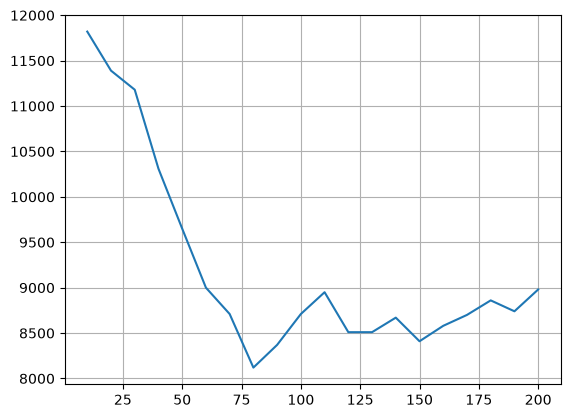

In [48]:
columns = ['n_estimators', 'auc','cost','tresh']
df_scores = pd.DataFrame(scores, columns=columns) 
plt.plot(df_scores.n_estimators, df_scores.cost)
plt.grid()

In [49]:
df_scores.loc[df_scores["cost"].idxmin()]

n_estimators      80.000000
auc                0.990608
cost            8120.000000
tresh              0.036700
Name: 7, dtype: float64

## XGBoost

In [50]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [51]:
def cost_metric(predt, dtrain):
    y_val = dtrain.get_label()

    tmax = 0.1
    thresholds = np.linspace(0, tmax, 1001)

    scores = for_thresh(thresholds, y_val, predt)

    min_idx = np.argmin(scores)
    min_score = scores[min_idx]

    n = 0

    while n < 2:
        if min_idx == 0:
            tmax /= 10

        elif min_idx == len(thresholds) - 1:
            tmax *= 10

        else:
            break

        thresholds = np.linspace(0, tmax, 1001)
        scores = for_thresh(thresholds, y_val, predt)
        min_idx = np.argmin(scores)
        min_score = scores[min_idx]

        n += 1

    return 'cost', float(min_score)

  0%|          | 0/5 [00:00<?, ?it/s]

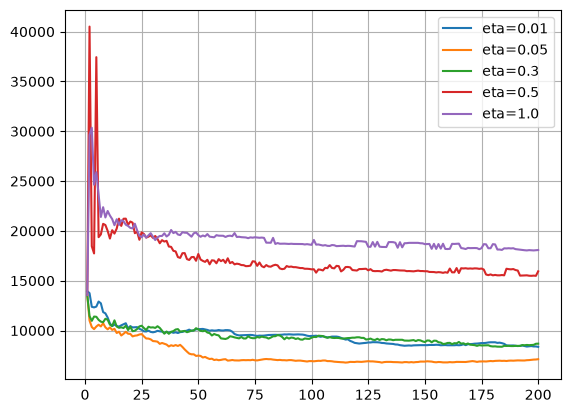

In [53]:
# Train XGBoost models for each eta and store cost results
scores = {} # dictionary to store results for each eta
etas = [0.01, 0.05, 0.3, 0.5, 1.0] # list of parameter values. in this case it is 'eta'.

for eta in tqdm(etas):
    evals_result = {}

    xgb_params = {
        'eta': eta,
        'max_depth': 15,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'disable_default_eval_metric': True,

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }


    model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=0,evals_result=evals_result,
                  evals=watchlist,custom_metric=cost_metric)
    columns = ['iter', 'train_cost', 'val_cost']
    train_cost = list(evals_result['train'].values())[0]
    val_cost = list(evals_result['val'].values())[0]

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_cost) + 1), train_cost, val_cost)),
        columns=columns
    )

    key = f'eta={eta}'
    scores[key] = df_results

    
for eta, df_results in scores.items():
    plt.plot(df_results.iter, df_results.val_cost, label=eta)

plt.legend()
plt.grid()

In [54]:
# Train XGBoost models for each max_depth and store cost results
scores = {} # dictionary to store results
depths = [5, 7, 10, 12, 15] # list of parameter values

for max_depth in tqdm(depths):
    evals_result = {}

    xgb_params = {
        'eta': 0.05,
        'max_depth': max_depth,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'disable_default_eval_metric': True,

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }


    model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=0,evals_result=evals_result,
                  evals=watchlist,custom_metric=cost_metric)
    columns = ['iter', 'train_cost', 'val_cost']
    train_cost = list(evals_result['train'].values())[0]
    val_cost = list(evals_result['val'].values())[0]

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_cost) + 1), train_cost, val_cost)),
        columns=columns
    )

    key = f'max_depth={max_depth}'
    scores[key] = df_results

for max_depth, df_results in scores.items():
    plt.plot(df_results.iter, df_results.val_cost, label=max_depth)

plt.legend()
plt.grid()

  0%|          | 0/5 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# Train XGBoost models for each min_child_weight and store cost results
scores = {} # dictionary to store results 
min_child_weights = [1, 5, 10] # list of parameter values

for min_child_weight in tqdm(min_child_weights):
    evals_result = {}

    xgb_params = {
        'eta': 0.05,
        'max_depth': 10,
        'min_child_weight': min_child_weight,

        'objective': 'binary:logistic',
        'disable_default_eval_metric': True,

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }


    model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=0,evals_result=evals_result,
                  evals=watchlist,custom_metric=cost_metric)
    columns = ['iter', 'train_cost', 'val_cost']
    train_cost = list(evals_result['train'].values())[0]
    val_cost = list(evals_result['val'].values())[0]

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_cost) + 1), train_cost, val_cost)),
        columns=columns
    )

    key = f'min_child_weight={min_child_weight}'
    scores[key] = df_results

    
for min_child_weight, df_results in scores.items():
    plt.plot(df_results.iter, df_results.val_cost, label=min_child_weight)

plt.legend()
plt.grid()

In [ ]:
# Train XGBoost models for each subsample and store AUC results
scores = {} # dictionary to store results 
subsamples = [0.6, 0.8, 1.0] # list of parameter values. 

for subsample in tqdm(subsamples):
    evals_result = {}

    xgb_params = {
        'eta': 0.05,
        'max_depth': 10,
        'min_child_weight': 1,
        'subsample': subsample,

        'objective': 'binary:logistic',
        'disable_default_eval_metric': True,

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }


    model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=0,evals_result=evals_result,
                  evals=watchlist,custom_metric=cost_metric)
    columns = ['iter', 'train_cost', 'val_cost']
    train_cost = list(evals_result['train'].values())[0]
    val_cost = list(evals_result['val'].values())[0]

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_cost) + 1), train_cost, val_cost)),
        columns=columns
    )

    key = f'subsample={subsample}'
    scores[key] = df_results

    
for subsample, df_results in scores.items():
    plt.plot(df_results.iter, df_results.val_cost, label=subsample)

plt.legend()
plt.grid()

### Cross-validation with xGBoost

In [ ]:
df_full_train=df_use
y_full_train = df_full_train.failure.values
del df_full_train['failure']

dv = DictVectorizer(sparse=False)

dicts_full_train = df_full_train.to_dict(orient='records')
X_full_train = dv.fit_transform(dicts_full_train)

features = list(dv.get_feature_names_out())
dtrain_full = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
watchlist = [(dtrain_full, 'train_full')]

In [ ]:
xgb_params = {
    'eta': 0.05, 
    'max_depth': 10,
    'min_child_weight': 1,
    'subsample': 1,
    
    'objective': 'binary:logistic',
    'nthread': 8,
    'disable_default_eval_metric': True,
    
    'seed': 1,
    'verbosity': 2,
}

model=xgb.cv(xgb_params, dtrain_full, num_boost_round=200, nfold=3,custom_metric=cost_metric, seed=1, stratified = True)

In [ ]:
plt.plot(model.index, model['test-cost-mean'], label='test')
plt.plot(model.index, model['train-cost-mean'], label='train')
plt.legend()
plt.grid()

In [ ]:
model['test-cost-mean'].idxmin() # choosing the final number for xGboost rounds

In [ ]:
# Train XGBoost models for each eta and store cost results
scores = {} # dictionary to store results for each eta
etas = [0.01, 0.05, 0.3] # list of parameter values. in this case it is 'eta'.

for eta in tqdm(etas):
    evals_result = {}

    xgb_params = {
        'eta': eta,
        'max_depth': 15,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'disable_default_eval_metric': True,

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }


    model=xgb.cv(xgb_params, dtrain_full, num_boost_round=200, nfold=3,custom_metric=cost_metric, seed=1, stratified = True)
    

    key = f'eta={eta}'
    scores[key] = model

In [ ]:
for eta, model in scores.items():
    plt.plot(model.index, model['train-cost-mean'], label=eta)
plt.title('Train') 
plt.legend()
plt.grid()

In [ ]:
for eta, model in scores.items():
    plt.plot(model.index, model['test-cost-mean'], label=eta)
plt.title('Test') 
plt.legend()
plt.grid()

In [ ]:
scores[f'eta={0.05}']['test-cost-mean'].idxmin()

### Final xGBoost model

In [ ]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
watchlist = [(dtrain, 'train'), (dval, 'val')]

xgb_params = {
    'eta': 0.05, 
    'max_depth': 10,
    'min_child_weight': 1,
    'subsample': 1,
    
    'objective': 'binary:logistic',
    'nthread': 8,
    'disable_default_eval_metric': True,
    
    'seed': 1,
    'verbosity': 1,
}
model = xgb.train(xgb_params, dtrain, num_boost_round=195,
                  verbose_eval=0,
                  evals=watchlist,custom_metric=cost_metric)

In [ ]:
# find the best threshold for the tuned xGboost model
y_pred = model.predict(dval)
print(roc_auc_score(y_val, y_pred))
print(cost_tresh(y_val,y_pred)) 

# Final model for deployment

In [55]:
df_full_train=df[important_feature]
y_full_train = df_full_train.failure.values
del df_full_train['failure']

In [56]:
df_test = pd.read_csv('data/aps_failure_test_set.csv')

In [57]:
df_test.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0,20,12,0,0,0,0,0,...,1098,138,412,654,78,88,0,0,0,0
1,neg,82,0,68,40,0,0,0,0,0,...,1068,276,1620,116,86,462,0,0,0,0
2,neg,66002,2,212,112,0,0,0,0,0,...,495076,380368,440134,269556,1315022,153680,516,0,0,0
3,neg,59816,na,1010,936,0,0,0,0,0,...,540820,243270,483302,485332,431376,210074,281662,3232,0,0
4,neg,1814,na,156,140,0,0,0,0,0,...,7646,4144,18466,49782,3176,482,76,0,0,0


In [58]:
df_test.shape

(16000, 171)

In [59]:
df_test=df_test.rename(columns={'class': 'failure'})
df_test.failure = (df_test.failure == 'pos').astype(int)
df_test.failure.value_counts()

failure
0    15625
1      375
Name: count, dtype: int64

In [60]:
for col in column_names:
    df_test[col] = pd.to_numeric(df_test[col], errors='coerce')

In [61]:
df_test=df_test.fillna(df[column_names].mean())

In [62]:
df_test=df_test[important_feature]

In [63]:
y_test = df_test.failure.values
del df_test['failure']

In [64]:
dv = DictVectorizer(sparse=False)

dicts_full_train = df_full_train.to_dict(orient='records')
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [65]:
features = list(dv.get_feature_names_out())
dtrain_full = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
dtest = xgb.DMatrix(X_test,feature_names=features)

In [66]:
xgb_params = {
    'eta': 0.05, 
    'max_depth': 10,
    'min_child_weight': 1,
    'subsample': 1,
    
    'objective': 'binary:logistic',
    'nthread': 8,
    'disable_default_eval_metric': True,
    
    'seed': 1,
    'verbosity': 1,
}
model = xgb.train(xgb_params, dtrain_full, num_boost_round=195,
                  verbose_eval=0, custom_metric=cost_metric)

In [67]:
y_pred = model.predict(dtest)
print(roc_auc_score(y_test, y_pred))
print(cost(y_test,y_pred,0.015))

0.9955664213333333
13690
